# Stage 4: Final evaluation on the hold-out season 2025-26

**This notebook is run once.** All choices (features, training windows, parameters, no recalibration) were made on the
walk-forward seasons 2015-16 to 2024-25 in notebooks 04-08. Here the chosen models are trained on the seasons just before
2025-26, exactly as in the last walk-forward fold, and scored on 2025-26, which no earlier notebook loaded. Nothing in
this notebook may be used to change a model; if a result here is surprising, it is reported, not fixed.

| Model | Role | Training seasons |
|---|---|---|
| `gbm_w2_ctx` | **main model**: LightGBM, default parameters, shot + context | 2023-24, 2024-25 |
| `logit_w1_ctx` | reference: spline logit + context | 2024-25 |
| `mlp_w2_ctx` | neural comparison, parameters chosen for the last walk-forward fold | 2023-24, 2024-25 |
| `gbm_w2`, `logit_w1` | the same without context | as above |
| `zone`, `null` | Stage 3 baselines | 2024-25 |

Context features for 2025-26 come from the v3 play-by-play format (`scripts/00_data/08_fetch_pbp_v3.py`); on 2024-25
the adapter reproduces the v2 features for 99.5-100% of shots. One difference: v3 has rebounds that the v2 archive misses,
so the rare `prev_event = "other"` (0.4% of training shots) does not occur in 2025-26.

## 0. Setup

In [1]:
%load_ext autoreload
# re-import src/xpts after every change, no kernel restart needed
%autoreload 2

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from xpts.baselines import ZoneBaseline, make_logit
from xpts.gbm import CONTEXT_FEATURES, GBM_FEATURES, GBMModel
from xpts.metrics import calibration_table, evaluate, paired_bootstrap
from xpts.mlp import MLPModel
from xpts.validation import HOLDOUT_SEASON

FIG_DIR = Path("../reports/figures")
KEY = ["GAME_ID", "GAME_EVENT_ID"]

df = pd.read_parquet("../data/processed/shots_features.parquet")
df = df.merge(pd.read_parquet("../data/processed/shots_context.parquet"), on=KEY, how="left", validate="1:1")
y = df["SHOT_MADE_FLAG"]
test = (df["SEASON"] == HOLDOUT_SEASON).to_numpy()
w1 = (df["SEASON"] == "2024-25").to_numpy()
w2 = df["SEASON"].isin(["2023-24", "2024-25"]).to_numpy()
print(f"hold-out {HOLDOUT_SEASON}: {test.sum():,} shots, {df.loc[test, 'GAME_ID'].nunique():,} games, "
      f"with context {df.loc[test, 'prev_event'].notna().mean():.5f}")

hold-out 2025-26: 219,160 shots, 1,230 games, with context 0.99995


## 1. Train once, score once

In [2]:
CTX = GBM_FEATURES + CONTEXT_FEATURES
MLP_LAST_FOLD = dict(hidden=64, layers=2, dropout=0.2, lr=0.003, epochs=31)  # chosen for test 2024-25 in 07_mlp
models = {
    "gbm_w2_ctx": (lambda: GBMModel(features=CTX), w2),
    "logit_w1_ctx": (lambda: make_logit(context=True), w1),
    "mlp_w2_ctx": (lambda: MLPModel(**MLP_LAST_FOLD), w2),
    "gbm_w2": (lambda: GBMModel(), w2),
    "logit_w1": (lambda: make_logit(), w1),
    "zone": (lambda: ZoneBaseline(), w1),
}
hold = df.loc[test, KEY + ["SEASON", "PLAYER_ID", "TEAM_ID", "shot_value", "action_group", "is_three", "prev_event"]].assign(y=y[test])
hold["null"] = y[w1].mean()
for name, (make, tr) in models.items():
    hold[name] = make().fit(df[tr], y[tr]).predict_proba(df[test])[:, 1]

order = ["gbm_w2_ctx", "logit_w1_ctx", "mlp_w2_ctx", "gbm_w2", "logit_w1", "zone", "null"]
res = pd.DataFrame({m: {**evaluate(hold["y"], hold[m]), "bias": hold["y"].mean() - hold[m].mean()} for m in order if m != "null"}).T
res.loc["null"] = {"n": len(hold), "log_loss": float(-(hold["y"] * np.log(hold["null"]) + (1 - hold["y"]) * np.log(1 - hold["null"])).mean()),
                   "brier": float(((hold["y"] - hold["null"]) ** 2).mean()), "auc": 0.5,
                   "bias": hold["y"].mean() - hold["null"].mean()}
display(res.round(4))
hold.to_parquet("../data/processed/holdout_predictions.parquet")

,n,log_loss,brier,auc,bias
gbm_w2_ctx,219160.0,0.6387,0.2248,0.6602,-0.0004
logit_w1_ctx,219160.0,0.6396,0.2252,0.6588,0.0007
mlp_w2_ctx,219160.0,0.6405,0.2255,0.6593,-0.0174
gbm_w2,219160.0,0.6399,0.2253,0.6581,-0.0004
logit_w1,219160.0,0.6405,0.2255,0.6572,0.0005
zone,219160.0,0.6570,0.2322,0.6369,0.0013
null,219160.0,0.6915,0.2492,0.5000,0.0038


In [3]:
# paired game-level bootstrap: main model against every other model
ci = pd.DataFrame({f"gbm_w2_ctx - {m}": paired_bootstrap(hold["y"], hold["gbm_w2_ctx"], hold[m], hold["GAME_ID"])
                   for m in ["logit_w1_ctx", "mlp_w2_ctx", "gbm_w2", "logit_w1", "zone"]}).T
display(ci.round(5))
display(pd.DataFrame({"logit_w1_ctx - logit_w1": paired_bootstrap(hold["y"], hold["logit_w1_ctx"], hold["logit_w1"], hold["GAME_ID"])}).T.round(5))

,diff,ci_low,ci_high,share_a_better
gbm_w2_ctx - logit_w1_ctx,-0.00087,-0.00112,-0.00061,1.0
gbm_w2_ctx - mlp_w2_ctx,-0.00175,-0.00207,-0.00140,1.0
gbm_w2_ctx - gbm_w2,-0.00119,-0.00142,-0.00099,1.0
gbm_w2_ctx - logit_w1,-0.00171,-0.00200,-0.00143,1.0
gbm_w2_ctx - zone,-0.01822,-0.01910,-0.01734,1.0


,diff,ci_low,ci_high,share_a_better
logit_w1_ctx - logit_w1,-0.00084,-0.00104,-0.00064,1.0


**Observations.**
- **The main model is the best on the hold-out season**: log loss 0.6387, Brier 0.2248, AUC 0.660, bias −0.04 p.p.
  This is at the level of the last walk-forward seasons (0.6389-0.6391), so the model did not overfit the development
  period and the choices made there carry over.
- It beats every other model with the game-level CI fully below zero: the logit with the same context by
  −0.0009 [−0.0011; −0.0006], the MLP by −0.0018, LightGBM without context by −0.0012, the Stage 3 logit by −0.0017 and
  the zone baseline by −0.018.
- Context helps again on new data: −0.0012 for LightGBM and −0.0008 for the logit, the same size as in 2018-19 to 2024-25.
- The MLP overestimates the whole season by 1.7 p.p. (bias −0.0174), the other models are within ±0.1 p.p. With the
  parameters of one fold and a single random seed the network is less stable than the other models, which agrees with
  section 1 of `07_mlp`.
- The order of the models is the same as in recent walk-forward seasons, so the conclusions of notebooks 05-08 hold.

## 2. Calibration on the hold-out season

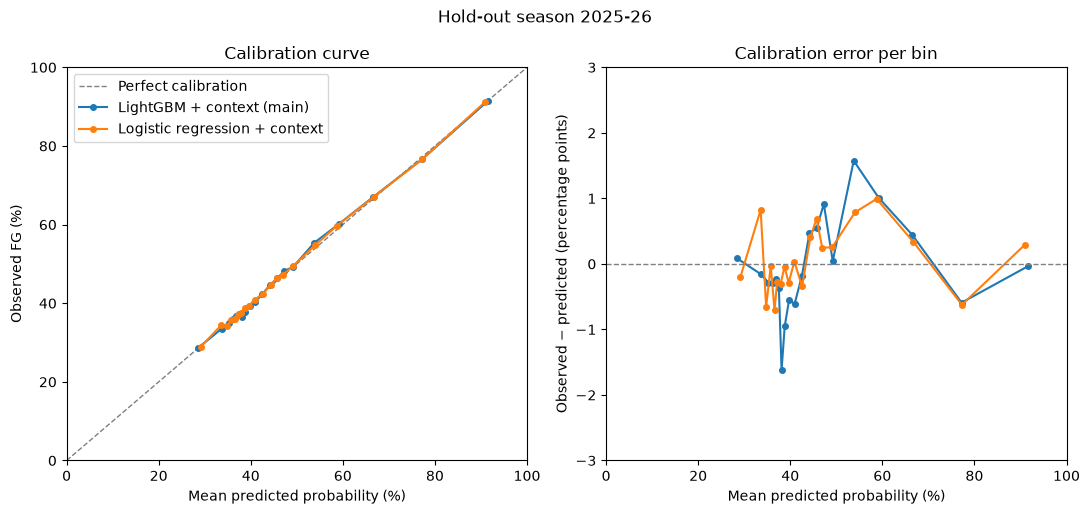

,ECE,bias
gbm_w2_ctx,0.0055,-0.0004
logit_w1_ctx,0.0042,0.0007


,n,fg_pct,bias_gbm_ctx,bias_logit_ctx
action_group,,,,
jumper,71092,0.372,-0.005,-0.004
layup,49212,0.575,0.005,0.004
pullup_jumper,29665,0.383,-0.008,-0.003
floater,19119,0.450,0.001,0.003
dunk,13474,0.886,-0.001,0.000
stepback_jumper,11366,0.379,0.003,0.006
fadeaway_jumper,10981,0.430,0.010,0.008
tip_putback,8570,0.558,0.009,0.009
hook,5681,0.488,0.012,0.005


,n,fg_pct,bias_gbm_ctx,bias_logit_ctx
is_three,,,,
0,128190,0.55,0.004,0.004
1,90970,0.36,-0.006,-0.003


,n,fg_pct,bias_gbm_ctx,bias_logit_ctx
prev_event,,,,
made_shot,64594,0.452,0.001,0.003
def_rebound,60669,0.476,-0.000,-0.001
off_rebound,25847,0.508,0.005,0.006
free_throw,18324,0.437,-0.011,-0.010
steal,15316,0.580,-0.002,-0.002
foul,10405,0.437,0.003,0.010
dead_turnover,9981,0.448,-0.004,-0.008
timeout,8324,0.432,-0.002,-0.005
period_start,2771,0.449,0.006,0.007


In [4]:
def ece(y_true, p, n_bins=20):
    cal = calibration_table(y_true, p, n_bins)
    return float((cal["n"] * (cal["y_mean"] - cal["p_mean"]).abs()).sum() / cal["n"].sum())


labels = {"gbm_w2_ctx": "LightGBM + context (main)", "logit_w1_ctx": "Logistic regression + context"}
fig, axes = plt.subplots(1, 2, figsize=(11, 5.2))
axes[0].plot([0, 100], [0, 100], color="grey", ls="--", lw=1, label="Perfect calibration")
for m, label in labels.items():
    cal = calibration_table(hold["y"], hold[m])
    axes[0].plot(100 * cal["p_mean"], 100 * cal["y_mean"], marker="o", ms=4, label=label)
    axes[1].plot(100 * cal["p_mean"], 100 * (cal["y_mean"] - cal["p_mean"]), marker="o", ms=4, label=label)
axes[0].set(xlabel="Mean predicted probability (%)", ylabel="Observed FG (%)", xlim=(0, 100), ylim=(0, 100), title="Calibration curve")
axes[0].legend()
axes[1].axhline(0, color="grey", ls="--", lw=1)
axes[1].set(xlabel="Mean predicted probability (%)", ylabel="Observed − predicted (percentage points)", xlim=(0, 100), ylim=(-3, 3),
            title="Calibration error per bin")
fig.suptitle(f"Hold-out season {HOLDOUT_SEASON}")
fig.tight_layout()
fig.savefig(FIG_DIR / "04_calibration_holdout.pdf")
plt.show()

display(pd.DataFrame({m: {"ECE": ece(hold["y"], hold[m]), "bias": hold["y"].mean() - hold[m].mean()} for m in labels}).T.round(4))
for col in ["action_group", "is_three", "prev_event"]:
    g = hold.groupby(col, observed=True)
    display(pd.DataFrame({"n": g.size(), "fg_pct": g["y"].mean(),
                          "bias_gbm_ctx": g["y"].mean() - g["gbm_w2_ctx"].mean(),
                          "bias_logit_ctx": g["y"].mean() - g["logit_w1_ctx"].mean()}).sort_values("n", ascending=False).round(3))

In [5]:
# expected vs actual points per shot for the league and per team (sum over shots, as in xPTS)
pts = hold["y"] * hold["shot_value"]
xpts = hold["gbm_w2_ctx"] * hold["shot_value"]
print(f"league: actual {pts.mean():.4f} pts/shot, expected {xpts.mean():.4f}, difference {pts.mean() - xpts.mean():+.4f}")
team = pd.DataFrame({"shots": hold.groupby("TEAM_ID").size(), "pts": pts.groupby(hold["TEAM_ID"]).sum(),
                     "xpts": xpts.groupby(hold["TEAM_ID"]).sum()})
team["diff_per_shot"] = (team["pts"] - team["xpts"]) / team["shots"]
display(team["diff_per_shot"].describe().round(4).to_frame().T)

league: actual 1.0913 pts/shot, expected 1.0947, difference -0.0034


,count,mean,std,min,25%,50%,75%,max
diff_per_shot,30.0,-0.0031,0.0354,-0.0634,-0.0229,-0.007,0.0127,0.0828


**Observations.**
- Calibration on 2025-26 is as good as in development: ECE 0.0055 (main) and 0.0042 (logit), errors per bin mostly
  within ±1 p.p. (one bin at 38% −1.6 p.p.), mean bias −0.04 p.p.
- Subgroups: every shot type within ±1.2 p.p. (hooks +1.2, fadeaways +1.0, pull-ups −0.8); 2PT +0.4 p.p., 3PT −0.6 p.p.
  The layup bias of the development seasons (+1.9 p.p.) is +0.5 p.p. here.
- League points: actual 1.0913 pts/shot, expected 1.0947 (−0.003). Per team the difference between actual and
  expected points per shot ranges from −0.063 to +0.083 (sd 0.035): this spread is shot making (and luck) of the teams,
  the quantity analysed in Stage 5.
- **Answer to RQ1**: on a season never used for any decision the model predicts with log loss 0.6387 and AUC 0.660,
  its probabilities are calibrated within about 1 p.p., and it is significantly better than all simpler models. The
  remaining limit is the missing defence / tracking information (`08_kaggle_defence`).